# เฉลย Lab 04 — วัดให้จริง

In [1]:
import numpy as np
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

Xc, yc = load_breast_cancer(return_X_y=True)
Xd, yd = load_diabetes(return_X_y=True)

### ข้อ 1 — ช่องว่าง train/test ของ k=1 คือ "คำโกหก"

k=1: train 1.000 vs test 0.937 — จำข้อสอบได้หมด (จุดที่ใกล้สุดของมันคือตัวมันเอง)
k=13: train 0.939 vs test 0.944 — เรียบ สุภาพ และ test ดีกว่าซะด้วยซ้ำ

In [2]:
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=42)
for k in [1, 13]:
    m = KNeighborsClassifier(n_neighbors=k).fit(Xtr, ytr)
    print(f"k={k:2d}: train={m.score(Xtr, ytr):.3f}  test={m.score(Xte, yte):.3f}")

k= 1: train=1.000  test=0.937
k=13: train=0.939  test=0.944


### ข้อ 2 — overfitting curve

sweet spot ~depth 3-4 (test 0.944) · หลังจากนั้น train พุ่งไป 1.000 แต่ test ค่อย ๆ ตก = เริ่มท่องจำรายคน

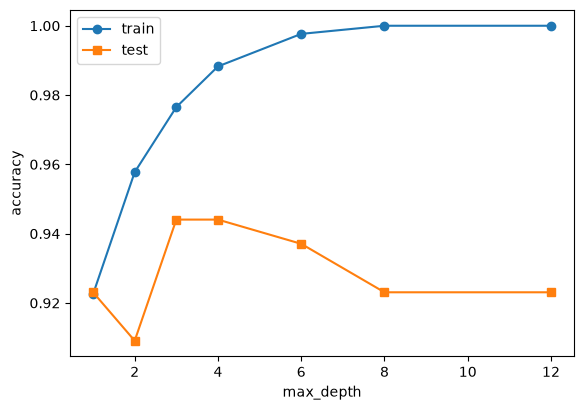

In [3]:
import matplotlib.pyplot as plt

depths = [1, 2, 3, 4, 6, 8, 12]
tr, te = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xtr, ytr)
    tr.append(t.score(Xtr, ytr)); te.append(t.score(Xte, yte))

plt.figure(figsize=(6.5, 4.5))
plt.plot(depths, tr, "o-", label="train")
plt.plot(depths, te, "s-", label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.show()

### ข้อ 3 — holdout vs CV

holdout 10 seeds: R² วิ่ง 0.359 → 0.586 (เกือบ 2 เท่าตัว!) · CV: 0.482 ± 0.049 — นิ่งกว่ามาก

In [4]:
vals = []
for seed in range(10):
    a, b, c, d = train_test_split(Xd, yd, test_size=0.25, random_state=seed)
    vals.append(LinearRegression().fit(a, c).score(b, d))
print(f"holdout 10 seeds: min={min(vals):.3f} max={max(vals):.3f}")

cv = cross_val_score(LinearRegression(), Xd, yd, cv=5)
print(f"5-fold CV        : mean={cv.mean():.3f} ± {cv.std():.3f}")

holdout 10 seeds: min=0.359 max=0.586
5-fold CV        : mean=0.482 ± 0.049


### ข้อ 4 — เทียบโมเดล fold เดียวกัน

accuracy ของ KNN (0.935) กับ RF (0.956) ใกล้กัน แต่ AUC ห่าง 0.966 vs 0.989 —
ถ้าดู accuracy อย่างเดียวจะประเมิน "ความสามารถจัดอันดับความเสี่ยง" ต่ำเกินจริง
(และ Dummy most_frequent ได้ acc 0.627 ฟรี ๆ — ไม่มี baseline ก็ไม่รู้ว่า 0.93 เยี่ยมแค่ไหน)

In [5]:
from sklearn.ensemble import RandomForestClassifier

skf = StratifiedKFold(5, shuffle=True, random_state=42)
for name, m in [("Dummy(most_freq)", DummyClassifier(strategy="most_frequent")),
                ("KNN(5)",          KNeighborsClassifier()),
                ("RandomForest",    RandomForestClassifier(random_state=42))]:
    acc = cross_val_score(m, Xc, yc, cv=skf).mean()
    auc = cross_val_score(m, Xc, yc, cv=skf, scoring="roc_auc").mean()
    print(f"{name:18s} acc={acc:.3f}  AUC={auc:.3f}")

Dummy(most_freq)   acc=0.627  AUC=0.500
KNN(5)             acc=0.935  AUC=0.966


RandomForest       acc=0.956  AUC=0.989


### ข้อ 5 — ถ้าคุณเป็นหมอ

confusion matrix: [[47, 6], [4, 86]] — FP 6 คน (ตรวจซ้ำเปล่า) / FN 4 คน (มะเร็งหลุด!)

In [6]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

knn = KNeighborsClassifier().fit(Xtr, ytr)
yp = knn.predict(Xte)
proba = knn.predict_proba(Xte)[:, 1]
print(confusion_matrix(yte, yp))
print(f"precision={precision_score(yte, yp):.3f}  recall={recall_score(yte, yp):.3f}  "
      f"f1={f1_score(yte, yp):.3f}  auc={roc_auc_score(yte, proba):.3f}")

[[47  6]
 [ 4 86]]
precision=0.935  recall=0.956  f1=0.945  auc=0.962


**คำตอบตัวอย่าง:** คัดกรองมะเร็ง = FN แพงกว่า FP มาก (มะเร็งที่หลุดอาจตาย / ตรวจซ้ำแค่เสียเงิน+เวลา)
→ เลือก **recall สูง** แม้ precision ลด โดยขยับ threshold ลงต่ำกว่า 0.5 แล้วยอมให้ส่งตรวจคนมากขึ้น